<a href="https://colab.research.google.com/github/lara-ms/Aula-M06/blob/main/ATV_13_Lara_Siecola.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Nome: Lara Moreira Siécola
## Matricula: 2365

## Atividade 13 – Análise dos Tempos de Resposta em uma Rede de Sensores Industriais

Uma equipe de engenharia está avaliando o desempenho de uma rede de sensores utilizada para monitorar variáveis de uma planta industrial. Nesse sistema, módulos embarcados enviam informações para uma estação central, que confirma o recebimento de cada mensagem.

Durante os ensaios, foram avaliados **20 módulos de telemetria** sob condições de teste semelhantes. Para cada módulo, a equipe registrou a **latência média de comunicação (em milissegundos)**, isto é, o tempo médio entre o envio de uma mensagem e a confirmação de seu recebimento. Os dados são **simulados para fins didáticos**.

A equipe deseja compreender o comportamento típico da comunicação e identificar possíveis diferenças de desempenho entre os módulos. Como referência do projeto, considera-se desejável uma latência média de até **130 ms** por módulo. Tempos elevados podem afetar a atualização das informações de monitoramento, mas conclusões sobre suas causas exigem investigação técnica adicional.

Utilize os dados da tabela a seguir para realizar as análises estatísticas propostas:

| Módulo de Telemetria | Latência Média (ms) |
|---------------------|--------------------|
| Módulo 01           | 104                |
| Módulo 02           | 111                |
| Módulo 03           | 116                |
| Módulo 04           | 109                |
| Módulo 05           | 113                |
| Módulo 06           | 76                 |
| Módulo 07           | 129                |
| Módulo 08           | 110                |
| Módulo 09           | 115                |
| Módulo 10           | 121                |
| Módulo 11           | 83                 |
| Módulo 12           | 182                |
| Módulo 13           | 108                |
| Módulo 14           | 93                 |
| Módulo 15           | 116                |
| Módulo 16           | 107                |
| Módulo 17           | 88                 |
| Módulo 18           | 112                |
| Módulo 19           | 119                |
| Módulo 20           | 125                |


In [ ]:
# Bibliotecas para visualização dos resultados
import seaborn as sns
import matplotlib.pyplot as plt

# Bibliotecas para análise estatística das medições
import numpy as np
import pandas as pd

In [ ]:
# Dados simulados dos ensaios de latência dos módulos de telemetria
# Cada valor representa a latência média registrada para um módulo, em ms.
tabela = {
    "Módulo de Telemetria": [
        "Módulo 01", "Módulo 02", "Módulo 03", "Módulo 04", "Módulo 05",
        "Módulo 06", "Módulo 07", "Módulo 08", "Módulo 09", "Módulo 10",
        "Módulo 11", "Módulo 12", "Módulo 13", "Módulo 14", "Módulo 15",
        "Módulo 16", "Módulo 17", "Módulo 18", "Módulo 19", "Módulo 20"
    ],
    "Latência Média (ms)": [
        104, 111, 116, 109, 113, 76, 129, 110, 115, 121,
        83, 182, 108, 93, 116, 107, 88, 112, 119, 125
    ]
}

dados = pd.DataFrame(tabela)
display(dados)

,Módulo de Telemetria,Latência Média (ms)
0,Módulo 01,104
1,Módulo 02,111
2,Módulo 03,116
3,Módulo 04,109
4,Módulo 05,113
5,Módulo 06,76
6,Módulo 07,129
7,Módulo 08,110
8,Módulo 09,115
9,Módulo 10,121


---
### Parte 1 - Tendência Central e Interpretação

Obs.: Se necessário, ordene os valores de latência em ordem crescente ou decrescente (rol).

In [ ]:
# Ordenar os módulos por latência média de comunicação (crescente)
df_ordenado = dados.sort_values(by='Latência Média (ms)', ascending=True).reset_index(drop=True)

# Média das latências medidas
media = dados['Latência Média (ms)'].mean()

# Mediana das latências medidas
mediana = dados['Latência Média (ms)'].median()

# Moda das latências (a série pode apresentar mais de uma moda)
moda = dados['Latência Média (ms)'].mode()

1. Calcule a média, a mediana e a moda dos tempos médios de resposta dos 20 módulos de telemetria. Apresente os resultados em milissegundos (ms).
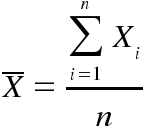
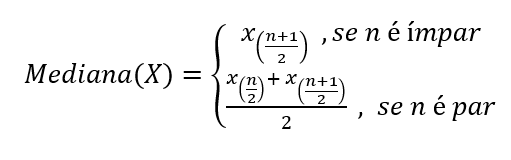


In [ ]:
display(df_ordenado)

# O codigo de "calculo" ja esta na celula anterior
print(f"\nMedia : {media:.2f} (ms)")
print(f"Mediana : {mediana:.2f} (ms)")
print(f"Moda : {moda.tolist()} (ms)")

# Verificando com a formula dada
soma = df_ordenado['Latência Média (ms)'].sum()
n = len(df_ordenado)

print(f"\nA media calculada é : {soma} / {n} = {soma/n:.2f} (ms)")

# Para mediana como são 20 elementos (PAR), ou seja, mediana = media dos termos centrais
t10 = df_ordenado['Latência Média (ms)'][9]
t11 = df_ordenado['Latência Média (ms)'][10]
print(f"\nA mediana calculada é : {t10} + {t11} / 2 = {(t10+t11)/2:.2f} (ms)")

# A moda é o valor que mais aparece e o 116 é o que mais aparece

,Módulo de Telemetria,Latência Média (ms)
0,Módulo 06,76
1,Módulo 11,83
2,Módulo 17,88
3,Módulo 14,93
4,Módulo 01,104
5,Módulo 16,107
6,Módulo 13,108
7,Módulo 04,109
8,Módulo 08,110
9,Módulo 02,111



Media : 111.85 (ms)
Mediana : 111.50 (ms)
Moda : [116] (ms)

A media calculada é : 2237 / 20 = 111.85 (ms)

A mediana calculada é : 111 + 112 / 2 = 111.50 (ms)


2. Os valores obtidos para média, mediana e moda são próximos? Qual dessas medidas representa melhor o desempenho típico de comunicação dos módulos analisados? Justifique com base nos resultados.

*Resposta*:

Os valores obtidos são bem próximos. A mediana representa melhor o desempenho típico de comunicação, pois não é afetada por valores atípicos, ou seja, seu valor nao é influenciado por valores extremos. Diferentemente da média que pode ser influenciada por valores absurdos, e no caso da moda ela pega apenas valores que aparecem mais vezes.

3. Identifique os módulos cujas latências estão mais distantes da média do conjunto. O que esses resultados podem indicar sobre o desempenho dos módulos e quais fatores técnicos poderiam ser investigados?

Resposta:

Os módulos mais distantes da média (111.85 ms) são :
- Módulo 12 (182 ms)
- Módulo 07 (129 ms)
- Módulo 06 (76 ms)
- Módulo 11 (83 ms)

O módulo 12 é o mais lento que os outros e ainda passa do limite de 130 ms. Já o módulo 06 é bem mais rápido. Fatores técnicos que podem ser identificados são : interferência, qualidade de sinal, dispositivos desatualidados ou defeituosos, configuração errada, distância longas.

---
### Parte 2 – Separatrizes (Quartis)

In [ ]:
# Cálculo dos quartis das latências médias de comunicação
quartis = dados['Latência Média (ms)'].quantile([0.25, 0.5, 0.75])

4. Calcule os quartis Q1, Q2 (mediana) e Q3 das latências médias dos módulos. Apresente os valores em milissegundos (ms).
<br>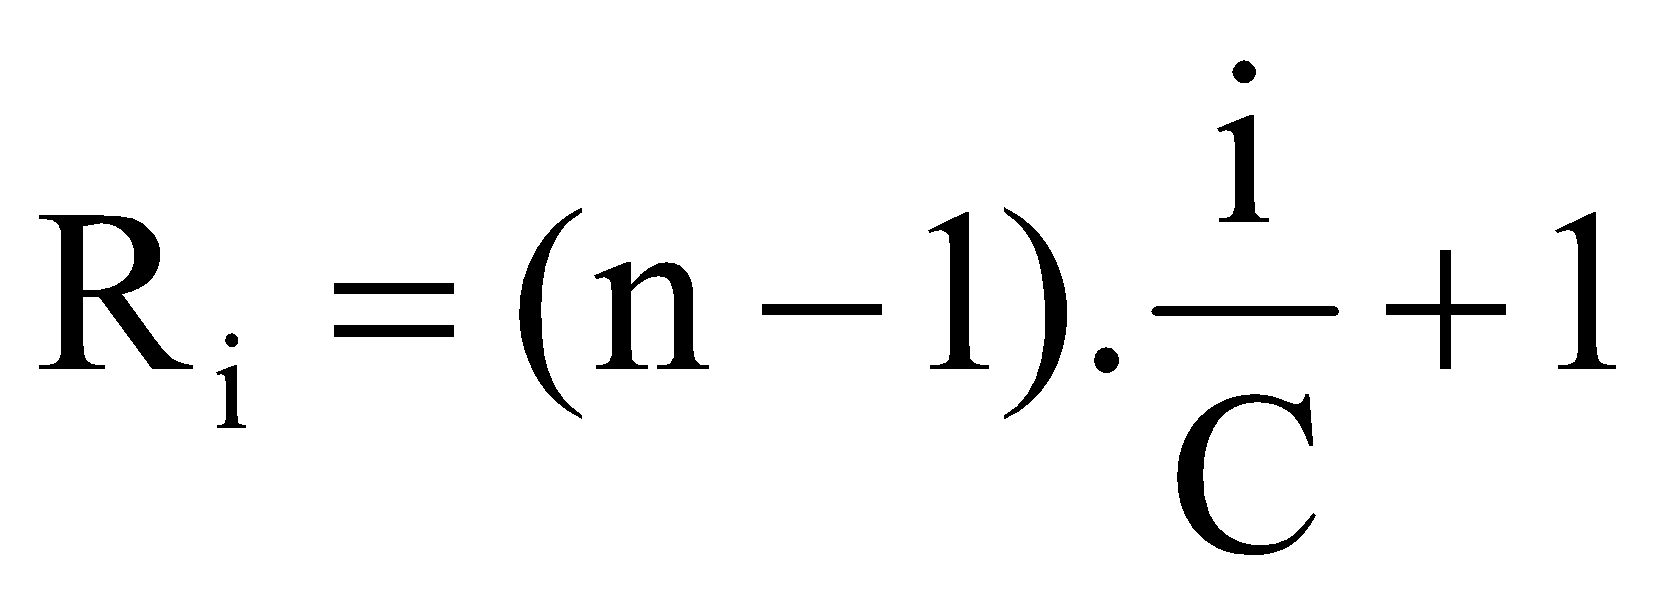

In [ ]:
# Separando os quartis ja calculados na celula anterior
Q1 = quartis[0.25]
Q2 = quartis[0.5]
Q3 = quartis[0.75]

print(f"Q1 : {Q1:.2f}")
print(f"Q2 : {Q2:.2f}")
print(f"Q3 : {Q3:.2f}")

# Abaixo do Q1
print("\nMódulos abaixo de Q1 :")
display(dados[dados['Latência Média (ms)'] < Q1])

# Acima do Q3
print("\nMódulos acima de Q3 :")
display(dados[dados['Latência Média (ms)'] > Q3])

Q1 : 106.25
Q2 : 111.50
Q3 : 116.75

Módulos abaixo de Q1 :


,Módulo de Telemetria,Latência Média (ms)
0,Módulo 01,104
5,Módulo 06,76
10,Módulo 11,83
13,Módulo 14,93
16,Módulo 17,88



Módulos acima de Q3 :


,Módulo de Telemetria,Latência Média (ms)
6,Módulo 07,129
9,Módulo 10,121
11,Módulo 12,182
18,Módulo 19,119
19,Módulo 20,125


5. Quais módulos apresentam latências abaixo de Q1? O que esse resultado representa em termos de rapidez de comunicação?

Resposta:

Os módulos abaixo de Q1 são :
- Módulo 01
- Módulo 06
- Módulo 11
- Módulo 14
- Módulo 17

Esses módulos representam 25% dos valores mais rápidos, ou seja, a comunicação mais ágil e as informações chegam mais rápido.

6. Quais módulos apresentam latências acima de Q3? Explique por que esses módulos podem exigir uma análise adicional do sistema de comunicação.

Resposta:

Os módulos abaixo de Q3 são :
- Módulo 07
- Módulo 10
- Módulo 12
- Módulo 19
- Módulo 20

Esses módulos representam 25% dos valores mais lentos, sendo um deles (Módulo 12) acima do limite. Eles exigem análise adicional pois podem atrasar a atualização do monitoramento.

---
### Parte 3 – Dispersão

In [ ]:
# Amplitude das latências: maior valor menos menor valor (ms)
latencias = dados['Latência Média (ms)']
amplitude = max(latencias) - min(latencias)

# Função para calcular a variância amostral das latências (ms²)
def variancia_latencia(valores):
    media = sum(valores) / len(valores)
    return sum((x - media) ** 2 for x in valores) / (len(valores) - 1)

# Função para calcular o desvio-padrão amostral das latências (ms)
def desvio_padrao_latencia(valores):
    return variancia_latencia(valores) ** 0.5

7. Calcule as seguintes medidas de dispersão para as latências médias dos módulos:

- Amplitude (ms):
<br>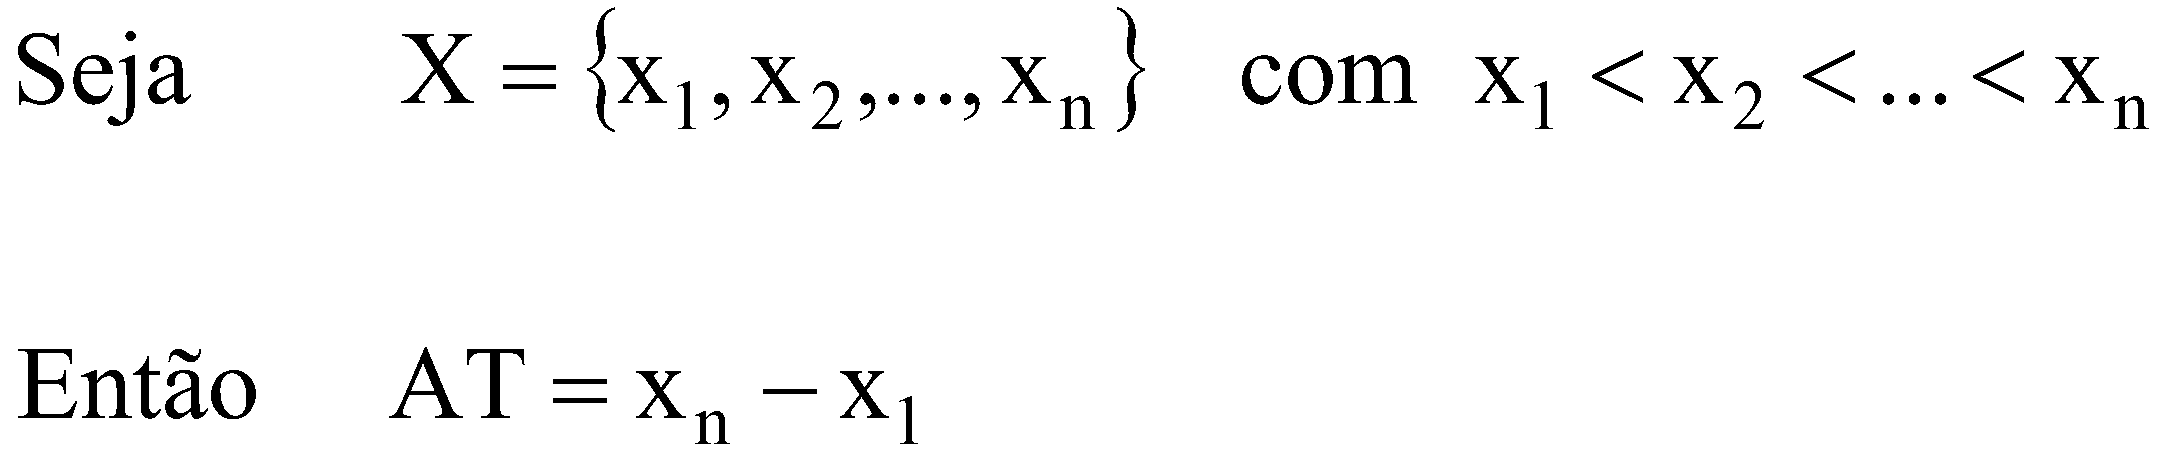

In [ ]:
print(f"Maior latência (Xn) : {max(latencias)} (ms)")
print(f"Menor latência (X1) : {min(latencias)} (ms)")

print(f"\nAmplitude (AT) : {max(latencias) - min(latencias)} (ms)")

Maior latência (Xn) : 182 (ms)
Menor latência (X1) : 76 (ms)

Amplitude (AT) : 106 (ms)


- Variância (amostral, em ms²):
<br>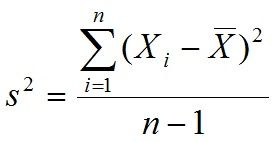

In [ ]:
variancia = variancia_latencia(latencias)
print(f"Variância (amostral, em ms²): {variancia:.2f} (ms²)")

Variância (amostral, em ms²): 459.08 (ms²)


- Desvio Padrão (amostral, em ms):
<br>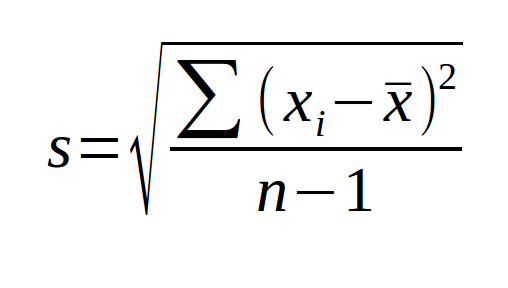


In [ ]:
desvio = desvio_padrao_latencia(latencias)
print(f"Desvio padrão (amostral, em ms): {desvio:.2f} (ms)")

Desvio padrão (amostral, em ms): 21.43 (ms)


8. As latências variam muito entre os módulos? Como essa dispersão pode influenciar a escolha de dispositivos, o diagnóstico de falhas e a confiabilidade do monitoramento industrial? Justifique com base nas medidas calculadas.

Resposta:

As latências variam muito entre os módulos, a amplitude é de 106 e a variancia de 459.08. Essa dispersão pode influenciar :
- Na escolha de dispositivos, pois pode-se preferir módulos com desempenho próximo do típico
- No diagnóstico de falhas, pois os módulos muito distantes da média devem ser os primeiros a serem investigados
- Na confiabilidade do monitoramento, pois se a dispersão for grande menos previsível é o tempo de atualização, ou seja, reduz a confiança do sistema.

---
### Parte 4 – Visualização de Dados

In [ ]:
# Função para visualizar a distribuição das latências por histograma
def plot_histograma_latencia(dados, coluna='Latência Média (ms)', bins=10):
    """
    Plota um histograma das latências registradas nos módulos.
    :param dados: DataFrame com os resultados dos ensaios
    :param coluna: Nome da coluna de latências, em milissegundos
    :param bins: Número de intervalos do histograma
    """
    plt.figure(figsize=(8, 5))
    plt.hist(dados[coluna], bins=bins, color='skyblue', edgecolor='black')
    plt.title('Distribuição das latências dos módulos de telemetria')
    plt.xlabel('Latência média de comunicação (ms)')
    plt.ylabel('Quantidade de módulos')
    plt.axvline(dados[coluna].mean(), color='red', linestyle='--',
                label=f'Média: {dados[coluna].mean():.2f} ms')
    plt.legend()
    plt.show()

# Função para visualizar a dispersão das latências por boxplot
def plot_boxplot_latencia(dados, coluna='Latência Média (ms)'):
    """
    Plota um boxplot para observar quartis, mediana e possíveis outliers.
    :param dados: DataFrame com os resultados dos ensaios
    :param coluna: Nome da coluna de latências, em milissegundos
    """
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=dados[coluna], color='lightgreen')
    plt.title('Dispersão das latências dos módulos de telemetria')
    plt.xlabel('Latência média de comunicação (ms)')
    plt.show()

9. Utilize a função `plot_histograma_latencia()` para criar um histograma da distribuição das latências médias dos 20 módulos. Observe a concentração e a dispersão dos valores.

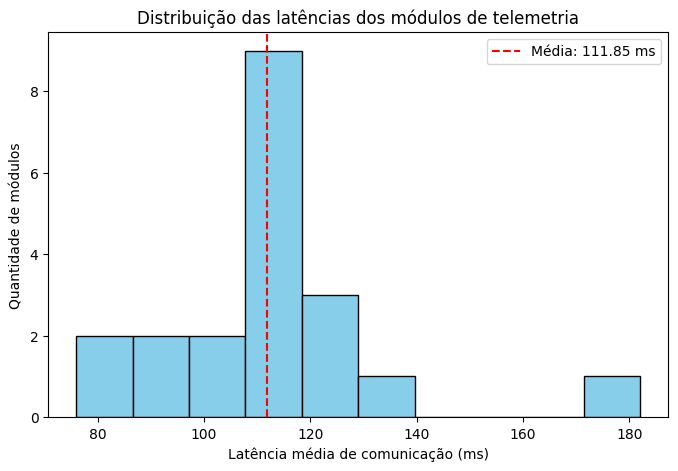

In [ ]:
plot_histograma_latencia(dados)

10. Utilize a função `plot_boxplot_latencia()` para criar um boxplot das latências. Identifique visualmente os quartis, a mediana e possíveis valores atípicos (outliers).

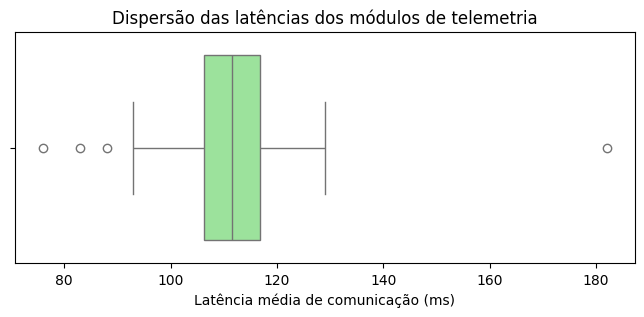

In [ ]:
plot_boxplot_latencia(dados)

11. Com base no boxplot, quais módulos podem ser considerados outliers? Explique como essas latências podem orientar a investigação de problemas de comunicação e a validação do requisito de 130 ms.

Resposta:

Com base no boxplot os módulos que devem ser considerados outliers são aqueles que representam como bolinhas fora do box e acima das linhas limites, sendo eles :
- Módulo 12 (182 ms)
- Módulo 06 (76 ms)
- Módulo 11 (83 ms)
- Módulo 17 (88 ms)

Nela é possível perceber e analisar que o Módulo 12 esta acima do limite devendo ser analisado com urgência. Já os demais módulos estão abaixo do limite e devem ser verificados apra ver o que há de diferente neles.